# Exploratory data analysis

Checks the UCI HAR data before any model is trained: sizes, class balance, participants, and basic quality. Only the official files are read. Figures for the paper are saved to `paper/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from har.config import PROJECT_ROOT
from har.data import load_dataset

FIGURES = PROJECT_ROOT / "paper" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

data = load_dataset()
names = data["activity_names"]

## 1. Sizes and participants

In [2]:
rows = []
for split in ("train", "test"):
    X, y, g = data[f"X_{split}"], data[f"y_{split}"], data[f"groups_{split}"]
    rows.append({"split": split, "windows": len(y), "features": X.shape[1],
                 "participants": len(np.unique(g)), "activities": len(np.unique(y))})
pd.DataFrame(rows).set_index("split")

,windows,features,participants,activities
split,,,,
train,7352,561,21,6
test,2947,561,9,6


The official training and test sets use different participants, so test results reflect unseen people.

In [3]:
train_ids = sorted(set(data["groups_train"].tolist()))
test_ids = sorted(set(data["groups_test"].tolist()))
print("train participants:", train_ids)
print("test participants: ", test_ids)
print("shared:", set(train_ids) & set(test_ids))

train participants: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
test participants:  [2, 4, 9, 10, 12, 13, 18, 20, 24]
shared: set()


## 2. Windows per activity

In [4]:
counts = pd.DataFrame({
    split: pd.Series(data[f"y_{split}"]).value_counts().sort_index()
    for split in ("train", "test")
})
counts.index = [names[i] for i in counts.index]
counts["train_%"] = (100 * counts["train"] / counts["train"].sum()).round(1)
counts["test_%"] = (100 * counts["test"] / counts["test"].sum()).round(1)
counts

,train,test,train_%,test_%
WALKING,1226,496,16.7,16.8
WALKING_UPSTAIRS,1073,471,14.6,16.0
WALKING_DOWNSTAIRS,986,420,13.4,14.3
SITTING,1286,491,17.5,16.7
STANDING,1374,532,18.7,18.1
LAYING,1407,537,19.1,18.2


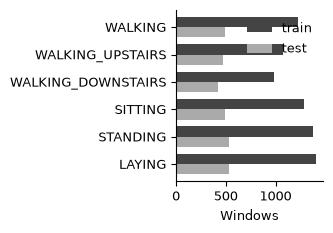

In [5]:
fig, ax = plt.subplots(figsize=(3.4, 2.4))
counts[["train", "test"]].plot.barh(ax=ax, color=["#444444", "#aaaaaa"], width=0.75)
ax.invert_yaxis()
ax.set_xlabel("Windows")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "class_distribution.pdf")
plt.show()

The classes are reasonably balanced (13% to 19% of the windows), so accuracy is not misleading. Macro metrics are still reported so every activity weighs the same.

## 3. Windows per participant

In [6]:
per_participant = pd.concat([
    pd.Series(data["groups_train"]).value_counts().rename("windows").to_frame().assign(split="train"),
    pd.Series(data["groups_test"]).value_counts().rename("windows").to_frame().assign(split="test"),
]).sort_index()
per_participant["windows"].describe().round(1)

count     30.0
mean     343.3
std       35.7
min      281.0
25%      317.8
50%      342.5
75%      371.0
max      409.0
Name: windows, dtype: float64

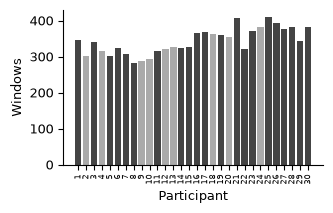

In [7]:
fig, ax = plt.subplots(figsize=(3.4, 2.2))
colors = per_participant["split"].map({"train": "#444444", "test": "#aaaaaa"})
ax.bar(per_participant.index.astype(str), per_participant["windows"], color=colors)
ax.set_xlabel("Participant")
ax.set_ylabel("Windows")
ax.tick_params(axis="x", labelsize=6, rotation=90)
fig.tight_layout()
fig.savefig(FIGURES / "windows_per_participant.pdf")
plt.show()

Each participant contributes between 281 and 409 windows, so no single person dominates training.

## 4. Do all participants cover all activities?

In [8]:
by_pair = pd.crosstab(
    np.concatenate([data["groups_train"], data["groups_test"]]),
    np.concatenate([data["y_train"], data["y_test"]]),
)
by_pair.columns = [names[c] for c in by_pair.columns]
print("participants missing an activity:", int((by_pair == 0).any(axis=1).sum()))
by_pair.describe().loc[["min", "max"]]

participants missing an activity: 0


,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
min,46.0,40.0,36.0,44.0,44.0,48.0
max,95.0,65.0,62.0,85.0,89.0,90.0


## 5. Data quality

In [9]:
X_all = np.vstack([data["X_train"], data["X_test"]])
quality = {
    "missing values": int(np.isnan(X_all).sum()),
    "min value": float(X_all.min()),
    "max value": float(X_all.max()),
    "duplicate rows": int(pd.DataFrame(X_all).duplicated().sum()),
    "constant features": int((X_all.std(axis=0) == 0).sum()),
}
pd.Series(quality)

missing values       0.0
min value           -1.0
max value            1.0
duplicate rows       0.0
constant features    0.0
dtype: float64

Features were normalized to the range [-1, 1] by the dataset authors. Tree models do not need scaling; the SVM will be scaled inside its pipeline anyway.

## Summary

- Official split: 7,352 training and 2,947 test windows, 561 features, from 21 and 9 different participants.
- Activities are roughly balanced and every participant covers all six.
- No missing values. These checks need no cleaning step before modeling.